# Lab 4-03：換成 Neo4j——MERGE 匯入、Cypher 多跳、讓 LLM 寫 Cypher

**目標**：把同一份 `triples.json` 匯入真正的圖資料庫 Neo4j，用 Cypher 重做上一本的多跳查詢，
最後讓 LLM 把問題翻成 Cypher（Text2Cypher），並且只准它讀、不准它寫。

**你會學到**
- `MERGE` 為什麼是匯入三元組的標準寫法（重跑不會長出重複節點）
- Cypher 就是把要找的子圖形狀畫成 ASCII
- Text2Cypher 的三道保險：給 schema、擋寫入關鍵字、用唯讀交易執行

**前置**：Lab 4-01 的 `data/triples.json`；Docker。先起一個 Neo4j 容器（只需做一次）：

```bash
docker run -d --name course-neo4j -p 7474:7474 -p 7687:7687 \
  -e NEO4J_AUTH=neo4j/<自己設一個密碼> neo4j:5
```

然後在 `.env` 加上 `NEO4J_PASSWORD=<同一個密碼>`（`NEO4J_URI` 預設 `bolt://localhost:7687`、`NEO4J_USER` 預設 `neo4j`）。
沒設密碼也能打開這本：連資料庫的 cell 會印「跳過」，LLM 產生 Cypher 的部分照樣能看。

**對應投影片**：「LPG 與 RDF 兩種模型」「Cypher 基本句型」「Lab 4 多跳提問流程」「選型：圖資料庫與 GraphRAG」「踩坑：別名、成本、語法」

![Neo4j 匯入與查詢流程](images/neo4j_flow.jpg)

*圖：上排是寫入，三元組用 MERGE 匯入 Neo4j；下排是讀取，LLM 把問題翻成 Cypher，先過朱紅色的「唯讀檢查」才准碰資料庫。*

## Step 1：連線

帳密一律從環境變數讀。連不上不讓整本 notebook 掛掉，而是把 `driver` 設成 `None`，後面的 cell 自己判斷要不要跳過。

In [1]:
import os

from dotenv import load_dotenv
from neo4j import GraphDatabase
from neo4j.exceptions import Neo4jError, ServiceUnavailable, AuthError

load_dotenv()
URI = os.getenv("NEO4J_URI", "bolt://localhost:7687")
USER = os.getenv("NEO4J_USER", "neo4j")
PASSWORD = os.getenv("NEO4J_PASSWORD")

driver = None
if not PASSWORD:
    print("沒有設定 NEO4J_PASSWORD：本 notebook 會跳過所有讀寫資料庫的步驟。設定方式見上方「前置」。")
else:
    try:
        driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
        driver.verify_connectivity()
        print("已連線：", driver.get_server_info().agent, URI)
    except (ServiceUnavailable, AuthError) as exc:
        print(f"連不上 Neo4j（{type(exc).__name__}）：檢查容器有沒有在跑、密碼對不對。後面的步驟會跳過。")
        driver = None

已連線： Neo4j/5.26.33 bolt://localhost:7687


兩個小工具：`write` 走一般交易，`read` 走**唯讀交易**。唯讀交易裡任何寫入，資料庫本身就會拒絕。
沒連線時兩者都只印「跳過」並回傳空清單。

In [2]:
def write(query: str, **params) -> list[dict]:
    if driver is None:
        print("（未連線，跳過寫入）")
        return []
    records, _, _ = driver.execute_query(query, params)
    return [r.data() for r in records]


def read(query: str, **params) -> list[dict]:
    if driver is None:
        print("（未連線，跳過查詢）")
        return []
    with driver.session() as session:
        return session.execute_read(lambda tx: [r.data() for r in tx.run(query, params)])

## Step 2：唯一性約束

先告訴資料庫：同一種標籤底下，`name` 不能重複。這是 MERGE 的好搭檔：
查「有沒有這個節點」會走索引，就算誰不小心用了 CREATE，資料庫也會擋下來。

In [3]:
import json
from pathlib import Path

data = json.loads(Path("data/triples.json").read_text(encoding="utf-8"))
LABELS = sorted({n["label"] for n in data["nodes"]})
print("標籤：", LABELS)

for label in LABELS:  # 標籤來自我們自己的檔案，不是使用者輸入，可以放心組進字串
    write(f"CREATE CONSTRAINT {label.lower()}_name IF NOT EXISTS FOR (n:{label}) REQUIRE n.name IS UNIQUE")
print(read("SHOW CONSTRAINTS YIELD name RETURN name ORDER BY name"))

標籤： ['Crew', 'Dream', 'Person', 'Place', 'Treasure']
[{'name': 'crew_name'}, {'name': 'dream_name'}, {'name': 'person_name'}, {'name': 'place_name'}, {'name': 'treasure_name'}]


## Step 3：用 MERGE 匯入

投影片「Cypher 基本句型」的寫入句型：**沒有才建，有就重用**。

```
MERGE (a:Person {name: '魯夫'})
MERGE (b:Crew {name: '草帽海賊團'})
MERGE (a)-[:MEMBER_OF]->(b)
```

一次送一條太慢，用 `UNWIND` 把整批清單送進去。標籤和關係型別每列不同，
Neo4j 5.26 起可以用 `$(變數)` 動態指定；更舊的版本只能把它們組進字串（記得先比對白名單）。

In [4]:
label_of = {n["name"]: n["label"] for n in data["nodes"]}

nodes = [{"name": n["name"], "label": n["label"], "aliases": n["aliases"]} for n in data["nodes"]]
rels = [{"s": t["subject"], "sl": label_of[t["subject"]], "rel": t["relation"],
         "o": t["object"], "ol": label_of[t["object"]], "source": t["source"]} for t in data["triples"]]

IMPORT_NODES = """
UNWIND $rows AS row
MERGE (n:$(row.label) {name: row.name})
SET n.aliases = row.aliases
"""
IMPORT_RELS = """
UNWIND $rows AS row
MATCH (a:$(row.sl) {name: row.s})
MATCH (b:$(row.ol) {name: row.o})
MERGE (a)-[r:$(row.rel)]->(b)
SET r.source = row.source
"""


def import_all() -> None:
    write(IMPORT_NODES, rows=nodes)
    write(IMPORT_RELS, rows=rels)


def counts() -> list[dict]:
    return read("MATCH (n) WITH count(n) AS nodes MATCH ()-[r]->() RETURN nodes, count(r) AS rels")


import_all()
print("第一次匯入：", counts())

第一次匯入： [{'nodes': 46, 'rels': 47}]


## Step 4：重跑一次，看會不會長出重複的東西

In [5]:
import_all()
print("第二次匯入：", counts())

第二次匯入： [{'nodes': 46, 'rels': 47}]


數字不變，這就是 MERGE 的價值：匯入管線可以放心重跑。
換成 CREATE 會怎樣？有唯一性約束時，資料庫會直接拒絕：

In [6]:
try:
    write("CREATE (:Person {name: '魯夫'})")
except Neo4jError as exc:
    print("被擋下：", exc.code)

被擋下： Neo.ClientError.Schema.ConstraintValidationFailed


沒有約束的話，這行會悄悄生出第二個「魯夫」，圖從此裂成兩半，這就是投影片說的「別名孤立」的親戚。

## Step 5：一跳查詢

Cypher 的讀法：圓括號是節點，方括號加箭頭是關係，`{name: $name}` 用參數帶值（跟 SQL 一樣，不要把值拼進字串）。

In [7]:
for row in read("""
MATCH (p:Person {name: $name})-[r]->(x)
RETURN type(r) AS relation, x.name AS target, labels(x)[0] AS label
""", name="魯夫"):
    print(row)

{'relation': 'CAPTAIN_OF', 'target': '草帽大船團', 'label': 'Crew'}
{'relation': 'DEFEATED', 'target': '阿龍', 'label': 'Person'}
{'relation': 'DREAMS_OF', 'target': '海賊王', 'label': 'Dream'}
{'relation': 'OWNS', 'target': '草帽', 'label': 'Treasure'}
{'relation': 'CAPTAIN_OF', 'target': '草帽海賊團', 'label': 'Crew'}
{'relation': 'OWNS', 'target': '橡膠果實', 'label': 'Treasure'}
{'relation': 'FROM', 'target': '風車村', 'label': 'Place'}


## Step 6：兩跳——投影片上那一句

「和魯夫同一個海賊團的人」。關係寫成 `CAPTAIN_OF|MEMBER_OF`，表示兩種都算。

In [8]:
rows = read("""
MATCH (h:Person {name: $name})-[:CAPTAIN_OF|MEMBER_OF]->(s:Crew)<-[:CAPTAIN_OF|MEMBER_OF]-(p:Person)
RETURN s.name AS crew, collect(p.name) AS mates
""", name="魯夫")
for row in rows:
    print(row["crew"], "：", "、".join(row["mates"]))

草帽大船團 ： 巴托洛米奧
草帽海賊團 ： 布魯克、佛朗基、吉貝爾、羅賓、喬巴、香吉士、騙人布、娜美、索隆


上一本 Step 5 的兩層迴圈，在這裡是一行圖形。

## Step 7：三跳——騙人布的父親所在海賊團的船長

把上一本 BFS 走出來的那條朱紅色路徑，直接畫成 Cypher：

In [9]:
rows = read("""
MATCH (u:Person {name: $name})-[:HAS_FATHER]->(f:Person)-[:MEMBER_OF]->(c:Crew)<-[:CAPTAIN_OF]-(cap:Person)
RETURN f.name AS father, c.name AS crew, cap.name AS captain
""", name="騙人布")
print(rows)

[{'father': '耶穌布', 'crew': '紅髮海賊團', 'captain': '香克斯'}]


如果你不知道中間要走哪些關係，只知道兩端，可以讓資料庫找最短路徑。
例如「巴托洛米奧」和「風車村」之間怎麼連：

In [10]:
rows = read("""
MATCH p = shortestPath((a {name: $a})-[*..6]-(b {name: $b}))
RETURN [n IN nodes(p) | n.name] AS names, [r IN relationships(p) | type(r)] AS rels
""", a="巴托洛米奧", b="風車村")
print(rows)

[{'names': ['巴托洛米奧', '草帽大船團', '魯夫', '風車村'], 'rels': ['MEMBER_OF', 'CAPTAIN_OF', 'FROM']}]


把這條路徑畫出來。注意 `[*..6]` 沒有方向：路徑上的箭頭不一定都朝同一邊。

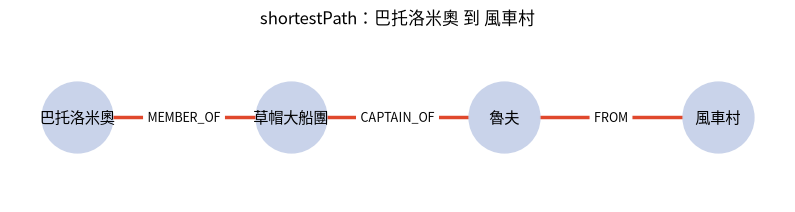

In [11]:
import matplotlib.pyplot as plt
import networkx as nx

from course_utils.viz import setup_cjk

setup_cjk()

if rows:
    names, rel_types = rows[0]["names"], rows[0]["rels"]
else:  # 沒連資料庫時，用預期的結果示意
    names, rel_types = ["巴托洛米奧", "草帽大船團", "魯夫", "風車村"], ["MEMBER_OF", "CAPTAIN_OF", "FROM"]

P = nx.path_graph(names)
pos = {n: (i, 0) for i, n in enumerate(names)}
plt.figure(figsize=(10, 2.2))
nx.draw_networkx_nodes(P, pos, node_color="#c9d3ea", node_size=2600)
nx.draw_networkx_labels(P, pos, font_family=plt.rcParams["font.sans-serif"][0], font_size=11)
nx.draw_networkx_edges(P, pos, edge_color="#e0482c", width=2.5, node_size=2600)
nx.draw_networkx_edge_labels(P, pos, edge_labels=dict(zip(zip(names, names[1:]), rel_types)), font_size=9)
plt.title("shortestPath：巴托洛米奧 到 風車村")
plt.axis("off")
plt.show()

## Step 8：讓 LLM 寫 Cypher（Text2Cypher）

前面每一句 Cypher 都是我們手寫的。能不能讓使用者用中文問，模型自己寫查詢？
跟模組 2 的 Text2SQL 一樣，關鍵是把 **schema** 和**範例**給它：它不知道我們的關係叫 `HAS_FATHER` 還是 `FATHER`。

In [12]:
from course_utils.llm import chat

SCHEMA = """節點標籤（都有 name 屬性）：Person, Crew, Treasure, Dream, Place
關係：
(:Person)-[:CAPTAIN_OF]->(:Crew)   船長
(:Person)-[:MEMBER_OF]->(:Crew)    船員
(:Person)-[:OWNS]->(:Treasure)     擁有（果實、刀、帽子）
(:Person)-[:DREAMS_OF]->(:Dream)   夢想
(:Person)-[:FROM]->(:Place)        出身
(:Person)-[:HAS_FATHER]->(:Person) 父親
(:Person)-[:BROTHER_OF]->(:Person) A 是 B 的結拜哥哥
(:Person)-[:DEFEATED]->(:Person)   打倒"""

T2C_SYSTEM = f"""你把中文問題翻成一句 Neo4j Cypher 查詢。
{SCHEMA}

規則：只能用 MATCH、WHERE、RETURN、ORDER BY、LIMIT；只用上面列出的標籤與關係；只輸出 Cypher，不要解釋、不要 ``` 符號。

範例
問題：娜美出身哪裡？
Cypher：MATCH (p:Person {{name: '娜美'}})-[:FROM]->(x:Place) RETURN x.name AS answer
問題：誰打倒了阿龍？
Cypher：MATCH (p:Person)-[:DEFEATED]->(:Person {{name: '阿龍'}}) RETURN p.name AS answer"""


def text2cypher(question: str, feedback: str = "") -> str:
    messages = [{"role": "system", "content": T2C_SYSTEM}, {"role": "user", "content": f"問題：{question}\nCypher："}]
    if feedback:
        messages.append({"role": "user", "content": feedback})
    raw = chat(messages)
    return raw.strip().removeprefix("```cypher").removeprefix("```").removesuffix("```").strip()


for q in ["喬巴吃了什麼果實？", "草帽海賊團的船長是誰？"]:
    print(q, "\n ", text2cypher(q))

喬巴吃了什麼果實？ 
  MATCH (p:Person {name: '喬巴'})-[:OWNS]->(t:Treasure) RETURN t.name AS answer
草帽海賊團的船長是誰？ 
  MATCH (p:Person {name: '草帽海賊團'})-[:CAPTAIN_OF]->(c:Person) RETURN c.name AS captain_name


第一題通常照著範例寫得很漂亮。第二題常見的錯：把「草帽海賊團」當成 `Person` 的名字、箭頭也畫反了。
語法完全正確，資料庫不會報錯，只會安靜地回傳空結果。這種錯最難抓，Step 10 會處理。

## Step 9：先擋寫入，再唯讀執行

模型產生的字串要當成**不可信的輸入**。兩道保險：

1. 程式先檢查：出現 `CREATE`、`MERGE`、`DELETE`、`SET` 這類寫入關鍵字就拒絕。
2. 就算漏網，也用唯讀交易（Step 1 的 `read`）執行，資料庫會拒絕任何寫入。

第 1 道擋大部分、給清楚的錯誤訊息；第 2 道才是真正的保證。

In [13]:
import re

WRITE_WORDS = re.compile(r"\b(CREATE|MERGE|DELETE|DETACH|SET|REMOVE|DROP|LOAD\s+CSV|CALL)\b", re.IGNORECASE)


def guard(cypher: str) -> None:
    hit = WRITE_WORDS.search(cypher)
    if hit:
        raise ValueError(f"拒絕執行：含有寫入或程序呼叫關鍵字 {hit.group(0)!r}")


for bad in ["MATCH (n) DETACH DELETE n", "MATCH (p:Person {name:'魯夫'}) SET p.name = '路飛'"]:
    try:
        guard(bad)
    except ValueError as exc:
        print(exc)

拒絕執行：含有寫入或程序呼叫關鍵字 'DETACH'
拒絕執行：含有寫入或程序呼叫關鍵字 'SET'


假設有人繞過了第 1 道（例如我們的正規表達式漏了某個寫法），第 2 道會怎麼反應？
直接把一句寫入丟進唯讀交易試試：

In [14]:
try:
    read("MATCH (p:Person {name: '魯夫'}) SET p.test = 1 RETURN p.name")
except Neo4jError as exc:
    print("資料庫拒絕：", exc.code)

資料庫拒絕： Neo.ClientError.Statement.AccessMode


## Step 10：錯了就把錯誤訊息還給模型

小模型寫的 Cypher 常見三種錯：語法錯、箭頭方向反了、用了 schema 裡沒有的關係名稱。
投影片「踩坑」的修法：把錯誤訊息（或「查無結果」）回饋給模型，讓它重寫一次。

In [15]:
def ask_graph(question: str, max_tries: int = 2) -> list[dict]:
    feedback = ""
    for attempt in range(1, max_tries + 1):
        cypher = text2cypher(question, feedback)
        print(f"  第 {attempt} 次：{cypher}")
        try:
            guard(cypher)
            rows = read(cypher)
        except (ValueError, Neo4jError) as exc:
            feedback = f"上一句 Cypher 執行失敗：{str(exc)[:200]}。請修正後只輸出新的 Cypher。"
            continue
        if rows or driver is None:
            return rows
        feedback = "上一句 Cypher 查無結果。檢查關係方向與名稱是否跟 schema 一致，只輸出新的 Cypher。"
    return []


for q in ["羅賓出身哪裡？", "騙人布的父親是哪個海賊團的成員？", "和索隆同一個海賊團的船長是誰？", "誰擁有和道一文字？"]:
    print(q)
    print("  結果：", ask_graph(q))

羅賓出身哪裡？
  第 1 次：MATCH (p:Person {name: '羅賓'})-[:FROM]->(x:Place) RETURN x.name AS answer
  結果： [{'answer': '歐哈拉'}]
騙人布的父親是哪個海賊團的成員？
  第 1 次：MATCH (b:Treasure {name: '騙人布'})-[:OWNS]->(c:Person)-[:HAS_FATHER]->(f:Person) RETURN f.name AS answer
  第 2 次：MATCH (b:Treasure {name: '騙人布'})-[:OWNS]->(c:Person)-[:HAS_FATHER]->(f:Person) RETURN f.name AS answer
  結果： []
和索隆同一個海賊團的船長是誰？
  第 1 次：MATCH (s:Person {name: '索隆'})-[:CAPTAIN_OF]->(c:Person) RETURN c.name AS captain_name
  第 2 次：MATCH (p:Person)-[:CAPTAIN_OF]->(c:Person)-[:MEMBER_OF]->(:Crew {name: '海賊團名稱'}) WHERE c.name = '索隆' RETURN p.name AS answer
  結果： []
誰擁有和道一文字？
  第 1 次：MATCH (p:Person)-[:OWNS]->(t:Treasure {name: '和道一文字'}) RETURN p.name AS answer
  結果： [{'answer': '索隆'}, {'answer': '古伊娜'}]


看一下哪幾題第一次就對、哪幾題要重試、哪幾題重試也救不回來。
多跳越多，模型越容易寫錯方向或漏一段。這就是投影片「Lab 4 多跳提問流程」的立場：
**高頻的問題寫成固定模板，模型只負責抽出名字**（像 Step 7 那樣帶 `$name` 參數）；Text2Cypher 留給長尾的臨時問題。

## 試試看

1. 打開 http://localhost:7474 ，用你的帳密登入，執行 `MATCH (n)-[r]->(m) RETURN n, r, m`，在瀏覽器看整張圖。
2. 把 `T2C_SYSTEM` 裡的範例刪掉，再跑 Step 10。錯誤率變多少？
3. 寫一個固定模板：給一個人名，回傳「他所屬海賊團的船長的夢想」。用 `read(..., name=...)` 跑索隆、騙人布、吉貝爾。

## 小結

- 匯入三元組用 `MERGE` 加唯一性約束：重跑不重複，誤用 CREATE 會被擋。
- Cypher 把要找的子圖畫成 ASCII；多跳就是把路徑接長，`shortestPath` 能在不知道中間關係時找出連法。
- Text2Cypher 要給 schema 與範例、擋寫入、唯讀執行、錯了回饋重試；高頻問題寫成模板更穩。下一本拿同一組題目，正式比較向量檢索和圖檢索。